# Practical 6: Hybrid Recommender System

## Aim
Implement and evaluate item-based collaborative filtering, content-based recommendation, and a weighted hybrid on MovieLens Small.

$
s_H(u,i)=\alpha s'_{CF}(u,i)+(1-\alpha)s'_{CB}(u,i)
$

All three models use the same chronological holdout and are evaluated with HR@10, MRR@10, and NDCG@10.

In [1]:
from google.colab import drive; drive.mount('/content/drive')
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

DATA_FOLDER = '/content/drive/MyDrive/mlsmall'
TOP_N = RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0
ALPHA = 0.60              # weight of the CF score in the hybrid
DEMO_USER_ID = 25

Mounted at /content/drive


## 1. Load data

In [2]:
ratings = pd.read_csv(f'{DATA_FOLDER}/ratings.csv')
movies  = pd.read_csv(f'{DATA_FOLDER}/movies.csv')
tags_path = f'{DATA_FOLDER}/tags.csv'
tags = pd.read_csv(tags_path) if os.path.exists(tags_path) else pd.DataFrame(columns=['movieId', 'tag'])

print('Ratings shape:', ratings.shape, '| Movies shape:', movies.shape, '| Tags loaded:', len(tags) > 0)
display(ratings.head(), movies.head())

Ratings shape: (100836, 4) | Movies shape: (9742, 3) | Tags loaded: True


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 2. Chronological train-test split and user-item matrix
Each user's latest rating is held out for testing.

In [3]:
latest = ratings.groupby('userId')['timestamp'].idxmax()
test_data, train_data = ratings.loc[latest], ratings.drop(index=latest)
print('Training ratings:', len(train_data), '| Testing ratings:', len(test_data))

train_matrix = train_data.pivot_table(index='userId', columns='movieId', values='rating')
movie_ids = train_matrix.columns.to_numpy()
pos = {m: i for i, m in enumerate(movie_ids)}          # movieId -> column position
print('User-item matrix:', train_matrix.shape)

Training ratings: 100226 | Testing ratings: 610
User-item matrix: (610, 9702)


## 3. Adjusted-cosine item representation (collaborative side)
Centre every rating by the user's mean, then L2-normalise each item's user vector.

In [4]:
centered = train_matrix.sub(train_matrix.mean(axis=1), axis=0).fillna(0.0)
item_user = csr_matrix(centered.T.to_numpy(dtype=np.float64))
norms = np.sqrt(item_user.multiply(item_user).sum(axis=1)).A1
norm_item_user = item_user.multiply(1.0 / np.where(norms > 0, norms, 1.0)[:, None]).tocsr()

## 4. Movie content (genres + tags) → TF-IDF
The same movie catalogue is used for all three models.

In [5]:
c = movies[['movieId', 'title', 'genres']].copy()
c['text'] = (c['genres'].fillna('').replace('(no genres listed)', '', regex=False)
             .str.replace('|', ' ', regex=False).str.lower())

t = tags[['movieId', 'tag']].dropna()
t = t.assign(tag=t['tag'].astype(str).str.lower().str.strip()).query("tag != ''").drop_duplicates()
c['text'] += ' ' + c['movieId'].map(t.groupby('movieId')['tag'].agg(' '.join)).fillna('')
c['text'] = c['text'].str.replace(r'\s+', ' ', regex=True).str.strip()

c = c.set_index('movieId').loc[movie_ids]
titles, genres = c['title'], c['genres']

tfidf = TfidfVectorizer(stop_words='english', lowercase=True)
content_features = tfidf.fit_transform(c['text'])
print('Content feature matrix:', content_features.shape)

Content feature matrix: (9702, 1673)


## 5. Manual cosine similarity

In [6]:
def cosine(query, matrix):
    """Cosine similarity between one sparse row `query` and every row of `matrix`."""
    query, matrix = csr_matrix(query), csr_matrix(matrix)
    dots  = (matrix @ query.T).toarray().ravel()
    denom = np.sqrt(matrix.multiply(matrix).sum(axis=1)).A1 * np.sqrt(query.multiply(query).sum())
    return np.divide(dots, denom, out=np.zeros_like(dots, dtype=float), where=denom > 0)

## 6. Collaborative and content scores for one user
- **CF:** adjusted-cosine item-item prediction `user_mean + Σ sim·deviation / Σ sim` (positive similarities only).
- **Content:** user profile = average TF-IDF vector of the items rated above the user's mean (weights `max(rating − mean, 0)`), scored by cosine.

In [7]:
def history_of(u):
    h = train_matrix.loc[u].dropna()
    return h, np.array([pos[m] for m in h.index], dtype=int)      # ratings, column positions of rated items

def cf_scores(u):
    h, rp = history_of(u)
    dev = h.to_numpy(float) - h.mean()
    S = (norm_item_user @ norm_item_user[rp].T).tocsr()           # similarity of every item to the rated ones
    S.data = np.maximum(S.data, 0.0); S.eliminate_zeros()         # keep positive similarities only
    num, den = S @ dev, np.asarray(S.sum(axis=1)).ravel()
    pred, ok = np.full(len(movie_ids), np.nan), den > 0
    pred[ok] = np.clip(h.mean() + num[ok] / den[ok], 0.5, 5.0)
    pred[rp] = np.nan                                             # never recommend already-rated items
    return pred

def content_scores(u):
    h, rp = history_of(u)
    w = np.maximum(h.to_numpy(float) - h.mean(), 0.0)
    if w.sum() == 0: w = h.to_numpy(float) / 5.0                  # user rated everything the same
    profile = csr_matrix(content_features[rp].T @ w / w.sum())
    s = cosine(profile, content_features); s[rp] = np.nan
    return s

## 7. Min-max normalisation and hybrid score

In [8]:
def minmax(s):
    out, ok = np.full_like(s, np.nan), np.isfinite(s)
    if ok.any():
        lo, hi = s[ok].min(), s[ok].max()
        out[ok] = 0.0 if hi == lo else (s[ok] - lo) / (hi - lo)
    return out

def hybrid_scores(u, alpha=ALPHA):
    cf, cb = cf_scores(u), content_scores(u)
    h = alpha * np.nan_to_num(minmax(cf)) + (1 - alpha) * np.nan_to_num(minmax(cb))
    h[~np.isfinite(cf) & ~np.isfinite(cb)] = np.nan               # no evidence from either model
    return cf, cb, h

def recommend_hybrid(u, n=TOP_N, alpha=ALPHA):
    cf, cb, h = hybrid_scores(u, alpha)
    top = np.argsort(-np.where(np.isfinite(h), h, -np.inf))[:n]
    top = top[np.isfinite(h[top])]
    return pd.DataFrame({'movieId': movie_ids[top], 'Movie': titles.iloc[top].values, 'Genres': genres.iloc[top].values,
                         'CF Score': cf[top], 'Content Score': cb[top], 'Hybrid Score': h[top]})

## 8. Demonstrate hybrid recommendations

TOP 10 HYBRID RECOMMENDATIONS FOR USER 25  (Hybrid = 0.60 CF + 0.40 Content)


,movieId,Movie,Genres,CF Score,Content Score,Hybrid Score
0,7307,Flesh & Blood (1985),Action|Adventure|Drama|War,5.000000,0.480059,0.989637
1,92234,Red Tails (2012),Action|Adventure|Drama|War,5.000000,0.480059,0.989637
2,156607,The Huntsman Winter's War (2016),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
3,38294,Beowulf & Grendel (2005),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
4,123553,In the Name of the King III (2014),Action|Adventure|Drama|Fantasy,5.000000,0.468534,0.980283
5,7458,Troy (2004),Action|Adventure|Drama|War,4.984144,0.480059,0.980123
6,5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama,5.000000,0.468151,0.979972
7,6990,The Great Train Robbery (1978),Action|Adventure|Comedy|Crime|Drama,5.000000,0.468151,0.979972
8,82765,Little Big Soldier (Da bing xiao jiang) (2010),Action|Adventure|Comedy|Drama|War,5.000000,0.461506,0.974579
9,2370,"Emerald Forest, The (1985)",Action|Adventure|Drama,5.000000,0.456241,0.970305


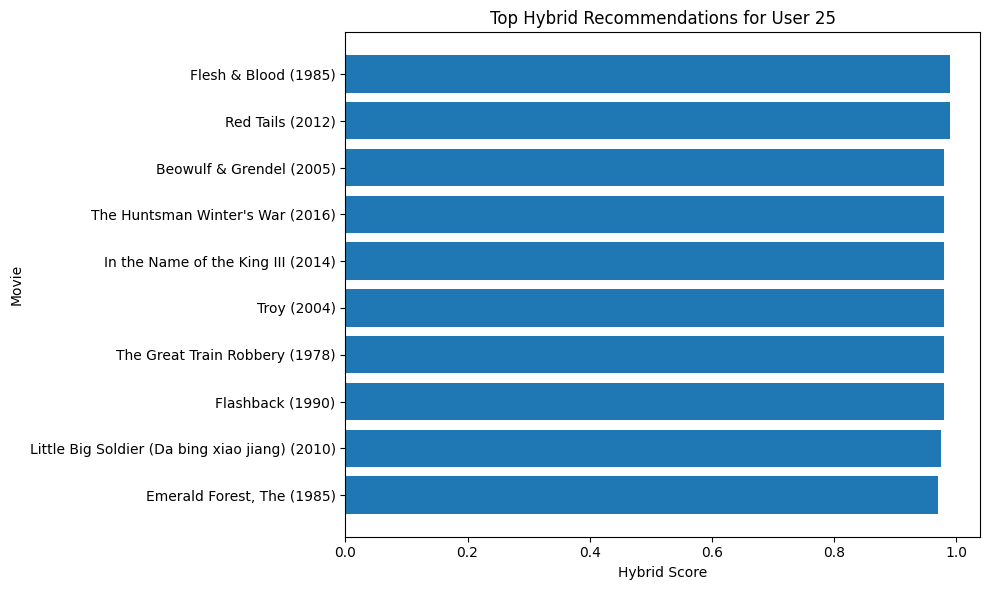

In [9]:
demo = recommend_hybrid(DEMO_USER_ID)
print(f'TOP {TOP_N} HYBRID RECOMMENDATIONS FOR USER {DEMO_USER_ID}  (Hybrid = {ALPHA:.2f} CF + {1 - ALPHA:.2f} Content)')
display(demo)

d = demo.sort_values('Hybrid Score')
plt.figure(figsize=(10, 6)); plt.barh(d['Movie'], d['Hybrid Score'])
plt.xlabel('Hybrid Score'); plt.ylabel('Movie'); plt.title(f'Top Hybrid Recommendations for User {DEMO_USER_ID}')
plt.tight_layout(); plt.show()

## 9. Ranking evaluation of CF, Content and Hybrid
Held-out items rated ≥ 4 are relevant; the rank of that item among the user's unseen movies gives HR, MRR and NDCG.

In [10]:
ev = test_data[(test_data['rating'] >= RELEVANCE_THRESHOLD)
               & test_data['userId'].isin(train_matrix.index) & test_data['movieId'].isin(movie_ids)]
print('Eligible evaluation users:', len(ev))

def rank_of(s, p):
    return None if not np.isfinite(s[p]) else int(np.sum(s[np.isfinite(s)] > s[p])) + 1

def metrics(rank, k=RANKING_K):
    hit = rank is not None and rank <= k
    return int(hit), (1 / rank if hit else 0.0), (1 / np.log2(rank + 1) if hit else 0.0)

rows = []
for r in ev.itertuples():
    p = pos[r.movieId]
    rows.append([metrics(rank_of(s, p)) for s in hybrid_scores(r.userId)])    # CF, Content, Hybrid
per_user = np.array(rows)                                                      # users x models x (HR, RR, NDCG)

comparison = pd.DataFrame(per_user.mean(axis=0),
                          index=pd.Index(['Collaborative Filtering', 'Content-Based', 'Hybrid'], name='Model'),
                          columns=[f'HR@{RANKING_K}', f'MRR@{RANKING_K}', f'NDCG@{RANKING_K}'])
print('MODEL COMPARISON'); display(comparison.reset_index())

Eligible evaluation users: 354
MODEL COMPARISON


,Model,HR@10,MRR@10,NDCG@10
0,Collaborative Filtering,0.005650,0.005650,0.005650
1,Content-Based,0.014124,0.012006,0.012516
2,Hybrid,0.000000,0.000000,0.000000


## 10. Hybrid improvement and comparison chart

HYBRID IMPROVEMENT


,Metric,Compared With,Baseline Value,Hybrid Value,Improvement (%)
0,HR@10,Collaborative Filtering,0.005650,0.0,-100.0
1,HR@10,Content-Based,0.014124,0.0,-100.0
2,MRR@10,Collaborative Filtering,0.005650,0.0,-100.0
3,MRR@10,Content-Based,0.012006,0.0,-100.0
4,NDCG@10,Collaborative Filtering,0.005650,0.0,-100.0
5,NDCG@10,Content-Based,0.012516,0.0,-100.0


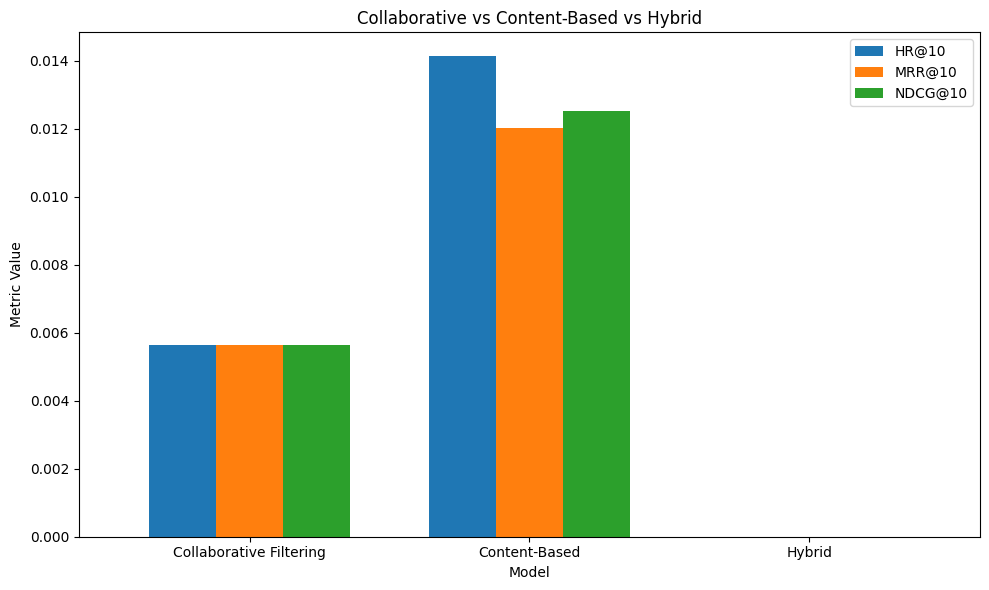

In [11]:
imp = pd.DataFrame([{
    'Metric': m, 'Compared With': b,
    'Baseline Value': comparison.loc[b, m], 'Hybrid Value': comparison.loc['Hybrid', m],
    'Improvement (%)': (comparison.loc['Hybrid', m] - comparison.loc[b, m]) / comparison.loc[b, m] * 100
                       if comparison.loc[b, m] > 0 else np.nan}
    for m in comparison.columns for b in ['Collaborative Filtering', 'Content-Based']])
print('HYBRID IMPROVEMENT'); display(imp)

comparison.plot.bar(figsize=(10, 6), width=0.72, rot=0)
plt.ylabel('Metric Value'); plt.title('Collaborative vs Content-Based vs Hybrid')
plt.tight_layout(); plt.show()